# Supervised Learning – Regression: Global AI Jobs 2026

**Business question:** What salary should an AI professional expect, based on the job's experience level, country, role, and company profile?

**Who benefits:**
- **Job seekers:** students and career shifters, including Filipinos considering remote or overseas AI work, can check whether an offer is fair.
- **HR teams:** set competitive pay ranges and avoid overpaying or losing candidates.
- **Recruitment agencies:** benchmark salaries across countries.

**Approach:**
- **Target:** `Salary_USD`, modeled as `log(salary)` to reduce the effect of extreme executive salaries.
- **Features:** Experience_Level, Country, Job_Title, Industry, Company_Size, Education_Required, AI_Specialization, Job_Type, Remote_Work_%, Company_AI_Maturity_1_10.
- **Success metrics:** R² ≥ 0.70, with MAE and RMSE as low as possible.

**Dataset:** Global AI Jobs 2026 (Kaggle), 5,000 job postings × 37 columns, synthetic. _TODO: add the Kaggle link and licence._

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
ai = pd.read_csv("global_ai_jobs_2026 (1).csv")
print("Shape:", ai.shape)
ai.head()

Shape: (5000, 37)


,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026


## 2. Data quality checks

1. **Synthetic data:** posting dates extend far into the future, so results show the method, not real market salaries.
2. **Sorted file:** rows are ordered by salary, so we must shuffle before splitting.
3. **Leakage:** `Salary_Min`, `Salary_Max`, and `Salary_Category` are derived from the salary itself and must be removed.
4. **Conflicting experience:** `Years_of_Experience` does not match `Experience_Level` in many rows.

In [3]:
posted = pd.to_datetime(ai["Posted_Date"])
print("Posting dates:", posted.min().date(), "to", posted.max().date())
print("Sorted by salary (descending)?", ai["Salary_USD"].is_monotonic_decreasing)
print("Missing values:", ai.isna().sum()[ai.isna().sum() > 0].to_dict())

Posting dates: 2026-01-01 to 2039-09-09
Sorted by salary (descending)? True
Missing values: {'Required_Certifications': 840}


In [4]:
# Years_of_Experience ranges 0-20 at every level, so it contradicts Experience_Level
print(ai.groupby("Experience_Level")["Years_of_Experience"].agg(["min", "median", "max"]))
conflicts = ai[(ai["Experience_Level"] == "Entry Level") & (ai["Years_of_Experience"] >= 10)]
print("Entry Level postings asking for 10+ years:", len(conflicts))

                  min  median  max
Experience_Level                  
Entry Level         0     7.0   20
Executive           0     5.0   20
Lead Level          0     7.0   20
Mid Level           0     7.0   20
Senior Level        0     7.0   20
Entry Level postings asking for 10+ years: 195


Because `Years_of_Experience` looks random relative to `Experience_Level`, we keep only `Experience_Level` as the experience feature.

In [5]:
LEAKAGE = ["Salary_Min", "Salary_Max", "Salary_Category"]
ai = ai.drop(columns=LEAKAGE)
ai = ai.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)  # undo the salary sort
ai["Salary_USD"].head()

0    179741.0
1    139147.0
2    136962.0
3    202121.0
4    232264.0
Name: Salary_USD, dtype: float64

## 3. Exploratory data analysis

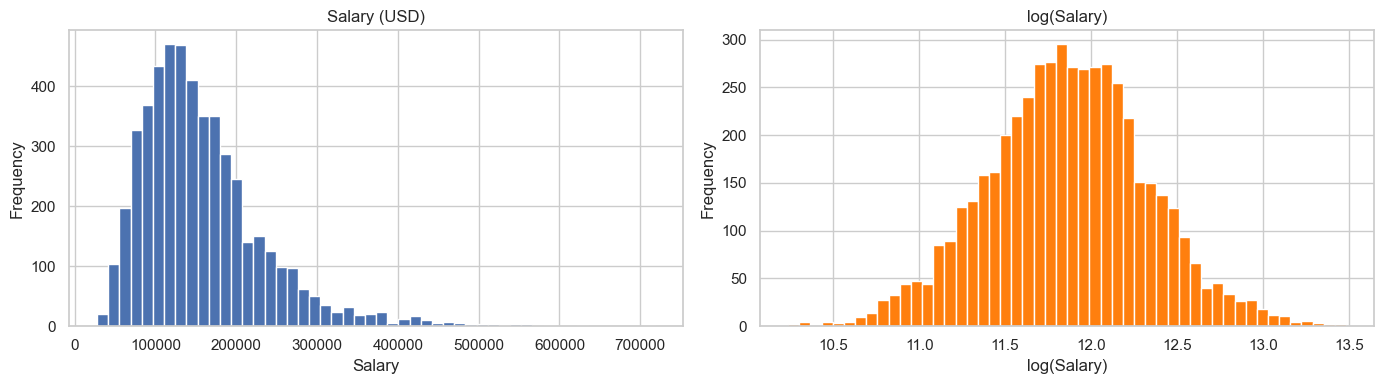

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ai["Salary_USD"].plot.hist(bins=50, ax=axes[0])
axes[0].set(title="Salary (USD)", xlabel="Salary")
np.log(ai["Salary_USD"]).plot.hist(bins=50, ax=axes[1], color="tab:orange")
axes[1].set(title="log(Salary)", xlabel="log(Salary)")
plt.tight_layout()
plt.show()

The raw salary is right-skewed (long tail of executive pay). The log transform makes it much closer to symmetric, which suits regression.

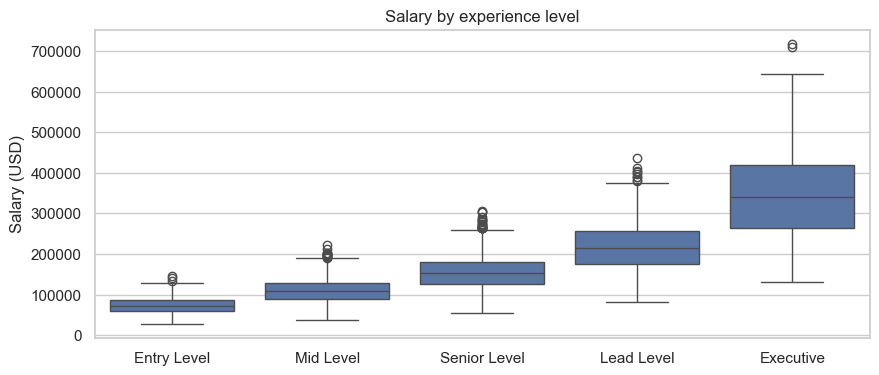

Experience_Level
Entry Level      72536.0
Mid Level       108376.0
Senior Level    154104.0
Lead Level      214833.0
Executive       339774.0
Name: Salary_USD, dtype: float64

In [7]:
LEVEL_ORDER = ["Entry Level", "Mid Level", "Senior Level", "Lead Level", "Executive"]

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=ai, x="Experience_Level", y="Salary_USD", order=LEVEL_ORDER, ax=ax)
ax.set(title="Salary by experience level", xlabel="", ylabel="Salary (USD)")
plt.show()

ai.groupby("Experience_Level")["Salary_USD"].median().reindex(LEVEL_ORDER).round()

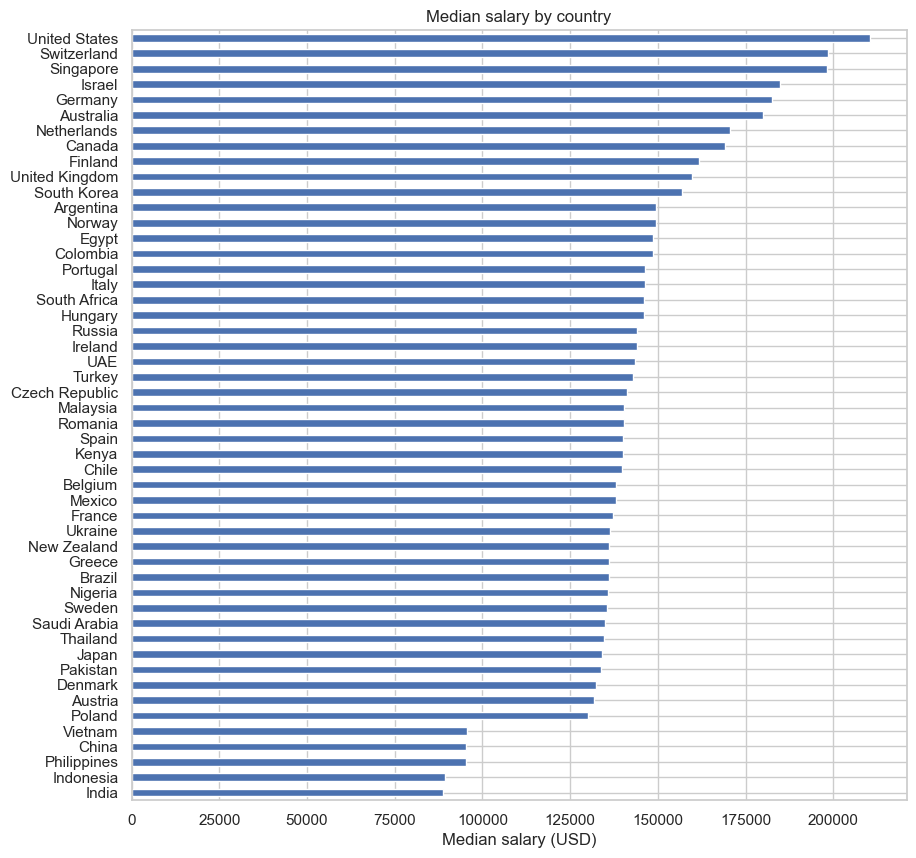

In [8]:
country_median = ai.groupby("Country")["Salary_USD"].median().sort_values()

fig, ax = plt.subplots(figsize=(10, 10))
country_median.plot.barh(ax=ax)
ax.set(title="Median salary by country", xlabel="Median salary (USD)", ylabel="")
plt.show()

Experience level and country show the clearest salary differences, which supports the assumption that they are the main drivers.

## 4. Features and train/test split

In [9]:
CATEGORICAL = ["Experience_Level", "Country", "Job_Title", "Industry", "Company_Size",
               "Education_Required", "AI_Specialization", "Job_Type"]
NUMERIC = ["Remote_Work_%", "Company_AI_Maturity_1_10"]

X = ai[CATEGORICAL + NUMERIC]
y = np.log(ai["Salary_USD"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])

Train: (4000, 10)  Test: (1000, 10)


## 5. Train and tune models

Linear Regression is the baseline. Each model is tuned with 5-fold cross-validation on the training set only.

In [10]:
candidates = {
    "Linear Regression (baseline)": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": [0.1, 1, 10, 30]}),
    "Random Forest": (RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                      {"model__n_estimators": [300], "model__max_depth": [None, 20],
                       "model__min_samples_leaf": [1, 5]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {"model__n_estimators": [300, 600], "model__learning_rate": [0.05, 0.1],
                           "model__max_depth": [2, 3]}),
}

searches = {}
for name, (model, grid) in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    searches[name] = GridSearchCV(pipe, grid, cv=5, scoring="r2", n_jobs=-1).fit(X_train, y_train)
    print(f"{name}: CV R² = {searches[name].best_score_:.3f}  {searches[name].best_params_}")

Linear Regression (baseline): CV R² = 0.790  {}
Ridge: CV R² = 0.790  {'model__alpha': 1}
Random Forest: CV R² = 0.774  {'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Gradient Boosting: CV R² = 0.792  {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 600}


## 6. Evaluate on the test set

In [11]:
def evaluate(name, search):
    pred_log = search.predict(X_test)
    actual, pred = np.exp(y_test), np.exp(pred_log)
    return {
        "Model": name,
        "CV R² (log)": search.best_score_,
        "Test R² (log)": r2_score(y_test, pred_log),
        "Test R² (USD)": r2_score(actual, pred),
        "MAE (USD)": mean_absolute_error(actual, pred),
        "RMSE (USD)": root_mean_squared_error(actual, pred),
    }

results = pd.DataFrame([evaluate(n, s) for n, s in searches.items()]).set_index("Model")
results.style.format({c: "{:.3f}" for c in results.columns if "R²" in c} | {"MAE (USD)": "${:,.0f}", "RMSE (USD)": "${:,.0f}"})

,CV R² (log),Test R² (log),Test R² (USD),MAE (USD),RMSE (USD)
Model,,,,,
Linear Regression (baseline),0.790,0.756,0.750,"$28,375","$37,208"
Ridge,0.790,0.757,0.750,"$28,344","$37,192"
Random Forest,0.774,0.744,0.720,"$29,179","$39,342"
Gradient Boosting,0.792,0.761,0.753,"$28,136","$36,918"


In [12]:
best_name = results["CV R² (log)"].idxmax()
best_model = searches[best_name].best_estimator_
print("Best model (chosen by CV R², not test R²):", best_name)

Best model (chosen by CV R², not test R²): Gradient Boosting


We pick the best model by **cross-validation** score so the test set stays an unbiased final check.

## 7. Inspect the best model

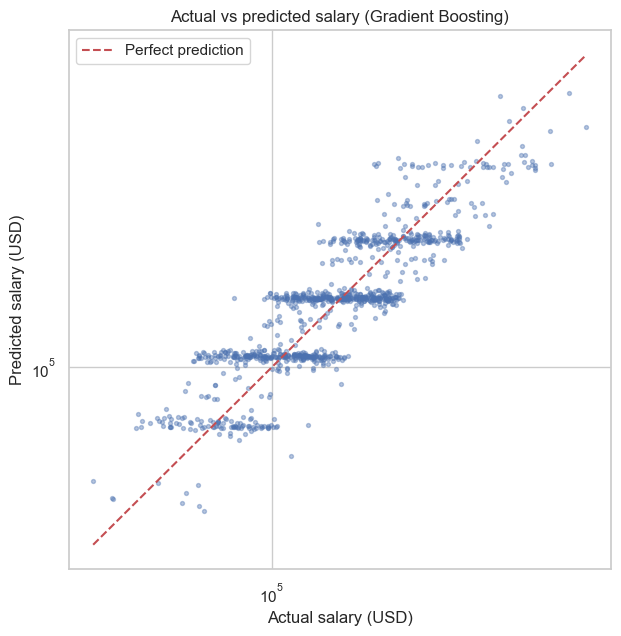

In [13]:
pred = np.exp(best_model.predict(X_test))
actual = np.exp(y_test)

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(actual, pred, s=8, alpha=0.4)
lims = [actual.min(), actual.max()]
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.set(xscale="log", yscale="log", title=f"Actual vs predicted salary ({best_name})",
       xlabel="Actual salary (USD)", ylabel="Predicted salary (USD)")
ax.legend()
plt.show()

In [ ]:
pred_log = best_model.predict(X_test)
residuals = y_test - pred_log

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(pred_log, residuals, s=8, alpha=0.4)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(title=f"Residuals vs predicted ({best_name})", xlabel="Predicted log(salary)",
            ylabel="Residual (actual − predicted)")
residuals.plot.hist(bins=40, ax=axes[1])
axes[1].set(title="Residual distribution", xlabel="Residual (log salary)")
plt.tight_layout()
plt.show()

_TODO after running: takeaway, e.g. are residuals centred on 0 with an even spread across predicted salaries, or is there a pattern (a funnel or curve) the model misses?_

In [14]:
# Typical error by level, in dollars and as a share of salary
errors = pd.DataFrame({"level": X_test["Experience_Level"], "actual": actual, "pred": pred})
errors["abs_error"] = (errors["actual"] - errors["pred"]).abs()
errors.groupby("level").agg(
    postings=("actual", "size"),
    median_salary=("actual", "median"),
    MAE=("abs_error", "mean"),
    median_pct_error=("abs_error", lambda e: (e / errors.loc[e.index, "actual"]).median() * 100),
).reindex(LEVEL_ORDER).round(0)

,postings,median_salary,MAE,median_pct_error
level,,,,
Entry Level,101,75883.0,13863.0,16.0
Mid Level,281,106741.0,19482.0,17.0
Senior Level,373,153628.0,26637.0,17.0
Lead Level,193,211790.0,38757.0,17.0
Executive,52,333093.0,73959.0,20.0


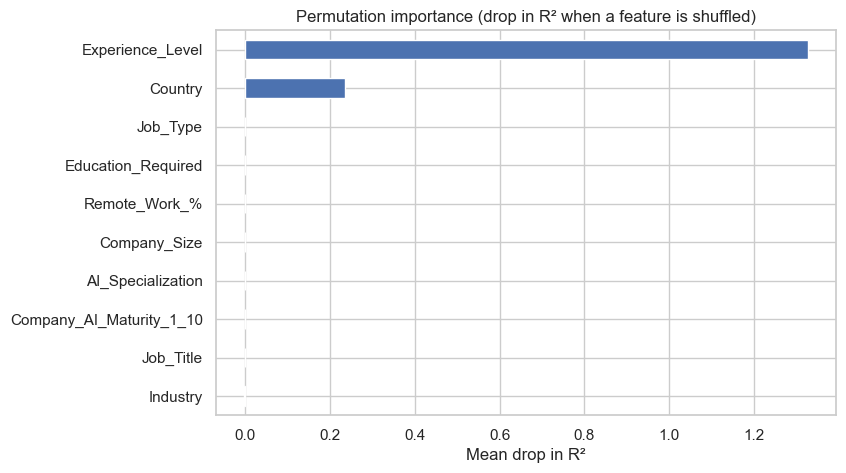

Experience_Level            1.327
Country                     0.235
Job_Type                    0.001
Education_Required          0.000
Remote_Work_%               0.000
Company_Size               -0.000
AI_Specialization          -0.000
Company_AI_Maturity_1_10   -0.000
Job_Title                  -0.000
Industry                   -0.002
dtype: float64

In [15]:
importance = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                                    random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importance.plot.barh(ax=ax)
ax.set(title="Permutation importance (drop in R² when a feature is shuffled)", xlabel="Mean drop in R²")
plt.show()
importance.sort_values(ascending=False).round(3)

**What the model learned:** Experience level is by far the strongest driver, followed by country. The other features add almost nothing, which is likely a quirk of this synthetic dataset. Gradient Boosting edges out Linear Regression only slightly, so the salary structure is close to "level × country" multipliers.

## 8. Example: estimate a salary for a new posting

A Filipino mid-level Machine Learning Engineer compares a local offer with the same role in other countries.

In [16]:
profile = {
    "Experience_Level": "Mid Level",
    "Job_Title": "Machine Learning Engineer",
    "Industry": "Technology",
    "Company_Size": "Large (501-5000)",
    "Education_Required": "Bachelor's",
    "AI_Specialization": "Deep Learning",
    "Job_Type": "Full-time",
    "Remote_Work_%": 50,
    "Company_AI_Maturity_1_10": 7,
}
countries = ["Philippines", "Singapore", "Japan", "United Kingdom", "United States"]
examples = pd.DataFrame([{**profile, "Country": c} for c in countries])
examples["Estimated salary (USD)"] = np.exp(best_model.predict(examples[CATEGORICAL + NUMERIC])).round(-2)
examples[["Country", "Experience_Level", "Job_Title", "Estimated salary (USD)"]]

,Country,Experience_Level,Job_Title,Estimated salary (USD)
0,Philippines,Mid Level,Machine Learning Engineer,78300.0
1,Singapore,Mid Level,Machine Learning Engineer,157200.0
2,Japan,Mid Level,Machine Learning Engineer,111100.0
3,United Kingdom,Mid Level,Machine Learning Engineer,127000.0
4,United States,Mid Level,Machine Learning Engineer,148400.0


## 9. Results vs success metrics

In [17]:
best = results.loc[best_name]
pd.DataFrame([
    {"Metric": "R² (log salary)", "Target": "≥ 0.70 (benchmark ~0.78)", "Result": f"{best['Test R² (log)']:.3f}",
     "Met?": "Yes" if best["Test R² (log)"] >= 0.70 else "No"},
    {"Metric": "MAE", "Target": "As low as possible", "Result": f"${best['MAE (USD)']:,.0f}",
     "Met?": "vs baseline ${:,.0f}".format(results.iloc[0]["MAE (USD)"])},
    {"Metric": "RMSE", "Target": "As low as possible", "Result": f"${best['RMSE (USD)']:,.0f}",
     "Met?": "vs baseline ${:,.0f}".format(results.iloc[0]["RMSE (USD)"])},
])

,Metric,Target,Result,Met?
0,R² (log salary),≥ 0.70 (benchmark ~0.78),0.761,Yes
1,MAE,As low as possible,"$28,136","vs baseline $28,375"
2,RMSE,As low as possible,"$36,918","vs baseline $37,208"


## 10. Assumptions, limitations, and next steps

**Assumptions**
- Experience level and country are the main drivers of salary (confirmed by the EDA and the feature importance).
- Past salary patterns will hold for future job postings.
- Each job posting is independent of the others.

**Limitations**
- The dataset is **synthetic** (posting dates extend to 2039), so results show the method, not real market salaries.
- `Salary_Min`, `Salary_Max`, and `Salary_Category` were removed to avoid data leakage.
- The file was sorted by salary, so it was shuffled before splitting.
- `Years_of_Experience` conflicts with `Experience_Level` (e.g., Entry Level with 20 years), so it was left out.
- MAE and RMSE in dollars are dominated by high-salary roles. Percentage error is a fairer view for entry-level jobs.
- Gradient Boosting beats the Linear Regression baseline only slightly, so a simple "level × country" model is almost as good.

**Suggested next steps**
- Re-train on real salary data (e.g. public salary surveys or job boards) to see if the same drivers hold.
- Predict a salary **range** (quantile regression) instead of a single number, since offers are negotiated within a range.
- Adjust for cost of living so salaries in different countries can be compared fairly.

**What this model should not be used for**
- Setting or negotiating real salaries. It is trained on synthetic data.
- Countries, roles, or experience levels that are not in the dataset.
- Judging an individual's worth. Salary also depends on skills, performance, and negotiation, which the model does not see.